In [19]:
import os

import cohere
from dotenv import load_dotenv

load_dotenv()
co = cohere.Client(os.environ["COHERE_API_KEY"])

response = co.embed(
    model="embed-v5.0-fast",
    texts=["Gafas de sol color gris", "Gafas de sol color negro", "Gafas de sol", "Gafas deportivas", "Lentes"],
    input_type="search_query",
    truncate="NONE",
)

print("Embeddings: {}".format(response.embeddings))

Embeddings: [[0.019259652, 0.00047457733, -0.044444703, 0.02518208, 0.0059411232, -0.001332234, -0.0031507425, -0.014656375, 0.049782157, -0.019295165, 0.009913118, -0.0074010165, 0.024280913, -0.00927251, 0.026187573, -0.0067047733, 0.025078556, 0.0014705638, 0.013771967, 0.007068389, 0.034933057, 0.03604133, 0.05636028, -0.008683032, -0.020732246, -0.008999779, -0.015513107, 0.014196728, 0.0035750282, -0.035155095, 0.020738868, 0.006520403, 0.014992638, -0.055966627, -0.011715006, -0.0022679034, 0.021747513, 0.030695293, 0.014646708, 0.04361442, -0.034721773, 0.004319273, 0.037680924, 0.008646835, 0.03711448, 0.018337129, -0.002968691, -0.017896224, -0.017467799, 0.014152566, 0.0253724, 0.025465965, 0.008925586, 0.036086142, 0.020242866, 0.00027261113, -0.022167856, -0.016211957, 0.08145453, -0.030341925, 0.017523197, 0.028154029, -0.01358246, 0.020501344, -0.029589646, 0.041893657, 0.014085044, 0.034042347, 0.018928614, 0.018542835, 0.021025443, 0.048908222, 0.024432871, 0.03682731,

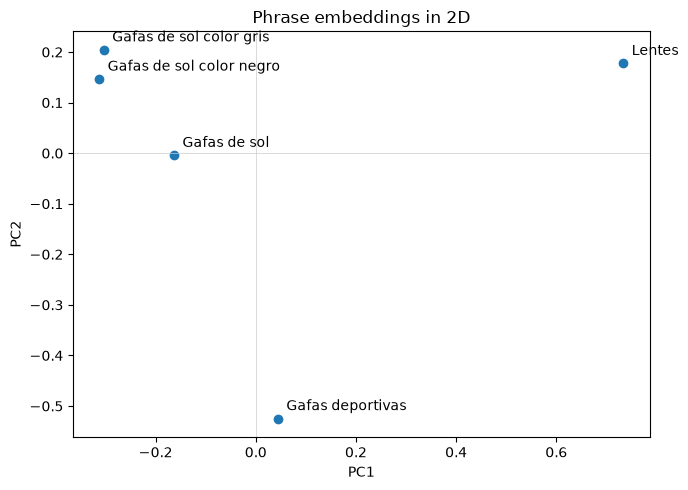

[[1.    0.747 0.784 0.622 0.389]
 [0.747 1.    0.818 0.635 0.389]
 [0.784 0.818 1.    0.746 0.515]
 [0.622 0.635 0.746 1.    0.512]
 [0.389 0.389 0.515 0.512 1.   ]]


In [21]:
import matplotlib.pyplot as plt
import numpy as np

texts = ["Gafas de sol color gris", "Gafas de sol color negro", "Gafas de sol", "Gafas deportivas", "Lentes"]
X = np.asarray(response.embeddings, dtype=np.float64)
X = X / np.linalg.norm(X, axis=1, keepdims=True)

centered = X - X.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xy = centered @ vt[:2].T

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(xy[:, 0], xy[:, 1])
for label, (x, y) in zip(texts, xy):
    ax.annotate(label, (x, y), xytext=(6, 6), textcoords="offset points")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Phrase embeddings in 2D")
ax.axhline(0, color="0.8", lw=0.5)
ax.axvline(0, color="0.8", lw=0.5)
fig.tight_layout()
plt.show()

print(np.round(X @ X.T, 3))

[[-0.3032  0.2045  0.3715]
 [-0.3123  0.1466 -0.3293]
 [-0.163  -0.0042 -0.0843]
 [ 0.0445 -0.5247  0.0506]
 [ 0.7339  0.1777 -0.0084]]


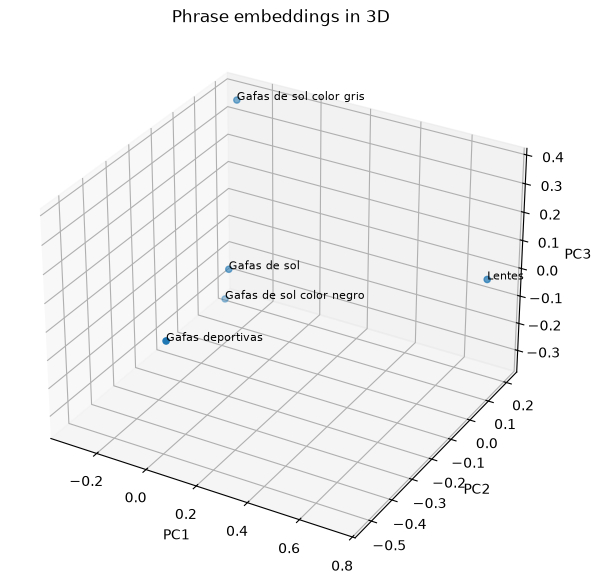

In [22]:
import matplotlib.pyplot as plt
import numpy as np

texts = [
    "Gafas de sol color gris",
    "Gafas de sol color negro",
    "Gafas de sol",
    "Gafas deportivas",
    "Lentes"
]
X = np.asarray(response.embeddings, dtype=np.float64)
X = X / np.linalg.norm(X, axis=1, keepdims=True)

centered = X - X.mean(axis=0)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
xyz = centered @ vt[:3].T

print(np.round(xyz, 4))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2])
for label, (x, y, z) in zip(texts, xyz):
    ax.text(x, y, z, label, fontsize=8)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Phrase embeddings in 3D")
fig.tight_layout()
plt.show()

In [27]:
import numpy as np


def embedding_coords(embeddings: np.ndarray, texts: list[str], dims: int) -> list[tuple]:
    """Project embeddings onto `dims` axes and L2-normalize each point.

    Returns one tuple per text: (text, c1, c2, ...) rounded to 4 decimals.
    Each coordinate vector v satisfies v / ||v||.
    """
    X = np.asarray(embeddings, dtype=np.float64)
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    centered = X - X.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    coords = centered @ vt[:dims].T
    coords = coords / np.linalg.norm(coords, axis=1, keepdims=True)
    coords = np.round(coords, 4)
    return [(text, *row.tolist()) for text, row in zip(texts, coords)]


texts = [
    "Gafas de sol color gris",
    "Gafas de sol color negro",
    "Gafas de sol",
    "Gafas deportivas",
    "Lentes",
]

print("2D  text, x, y")
for row in embedding_coords(response.embeddings, texts, 2):
    print(row)

print("3D  text, x, y, z")
for row in embedding_coords(response.embeddings, texts, 3):
    print(row)

2D  text, x, y
('Gafas de sol color gris', -0.8291, 0.5591)
('Gafas de sol color negro', -0.9052, 0.425)
('Gafas de sol', -0.9997, -0.0255)
('Gafas deportivas', 0.0845, -0.9964)
('Lentes', 0.9719, 0.2354)
3D  text, x, y, z
('Gafas de sol color gris', -0.5816, 0.3922, 0.7127)
('Gafas de sol color negro', -0.6547, 0.3074, -0.6905)
('Gafas de sol', -0.8879, -0.0227, -0.4594)
('Gafas deportivas', 0.0841, -0.9919, 0.0956)
('Lentes', 0.9718, 0.2354, -0.0112)


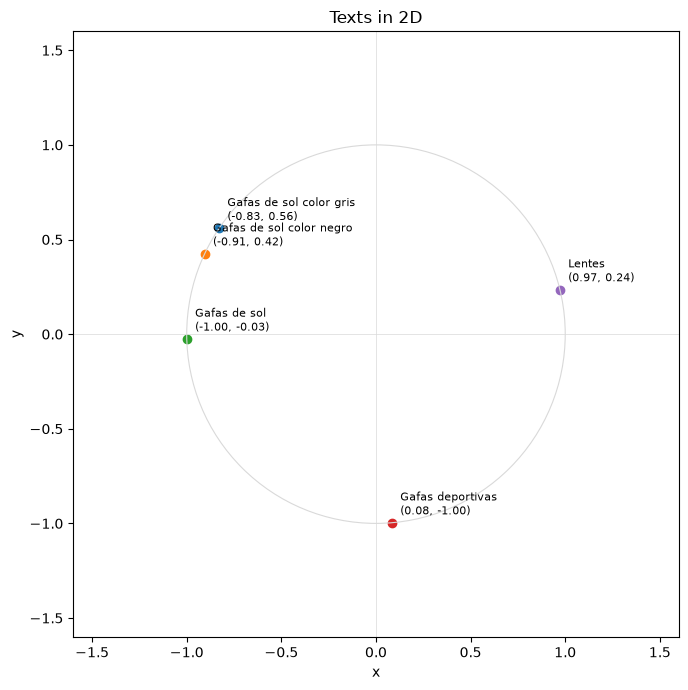

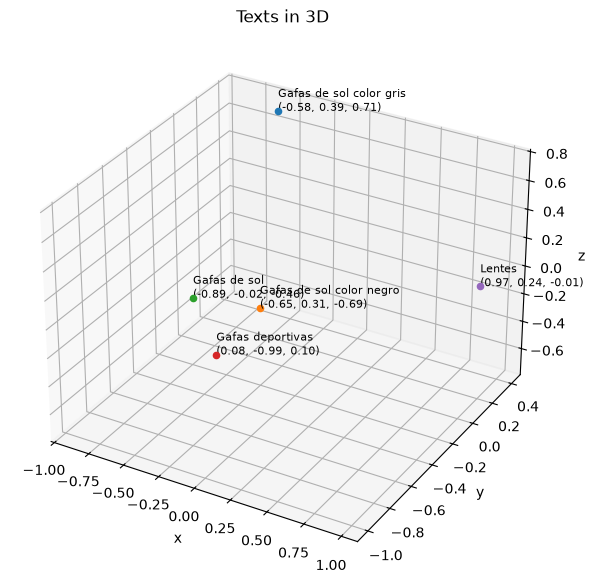

In [29]:
import matplotlib.pyplot as plt
import numpy as np


def embedding_coords(embeddings: np.ndarray, texts: list[str], dims: int) -> list[tuple]:
    """Project embeddings onto `dims` axes and L2-normalize each point.

    Returns one tuple per text: (text, c1, c2, ...) rounded to 4 decimals.
    """
    X = np.asarray(embeddings, dtype=np.float64)
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    centered = X - X.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    coords = centered @ vt[:dims].T
    coords = coords / np.linalg.norm(coords, axis=1, keepdims=True)
    coords = np.round(coords, 4)
    return [(text, *row.tolist()) for text, row in zip(texts, coords)]


texts = [
    "Gafas de sol color gris",
    "Gafas de sol color negro",
    "Gafas de sol",
    "Gafas deportivas",
    "Lentes",
]

points_2d = embedding_coords(response.embeddings, texts, 2)
fig, ax = plt.subplots(figsize=(7, 7))
for label, x, y in points_2d:
    ax.scatter(x, y)
    ax.annotate(
        f"{label}\n({x:.2f}, {y:.2f})",
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8,
    )
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.85", lw=0.8))
ax.set_aspect("equal")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.axhline(0, color="0.85", lw=0.5)
ax.axvline(0, color="0.85", lw=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Texts in 2D")
fig.tight_layout()
plt.show()

points_3d = embedding_coords(response.embeddings, texts, 3)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for label, x, y, z in points_3d:
    ax.scatter(x, y, z)
    ax.text(x, y, z, f"{label}\n({x:.2f}, {y:.2f}, {z:.2f})", fontsize=8)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Texts in 3D")
fig.tight_layout()
plt.show()

In [32]:
import numpy as np


def pairwise_similarity(points: list[tuple]) -> np.ndarray:
    """Map cosine similarity of the projected points to [0, 1].

    1 means the same direction. 0 means opposite directions.
    """
    coords = np.asarray([row[1:] for row in points], dtype=np.float64)
    coords = coords / np.linalg.norm(coords, axis=1, keepdims=True)
    cosine = coords @ coords.T
    return np.round((cosine + 1) / 2, 4)


def show_similarity(points: list[tuple]) -> None:
    """Print a labeled similarity matrix. The diagonal is 1."""
    labels = [row[0] for row in points]
    score = pairwise_similarity(points)
    width = max(len(label) for label in labels)
    print(" " * width + "".join(f"{label:>28}" for label in labels))
    for label, row in zip(labels, score):
        print(f"{label:<{width}}" + "".join(f"{value:28.4f}" for value in row))


print("2D")
show_similarity(embedding_coords(response.embeddings, texts, 2))
print()
print("3D")
show_similarity(embedding_coords(response.embeddings, texts, 3))

2D
                             Gafas de sol color gris    Gafas de sol color negro                Gafas de sol            Gafas deportivas                      Lentes
Gafas de sol color gris                       1.0000                      0.9941                      0.9073                      0.1864                      0.1629
Gafas de sol color negro                      0.9941                      1.0000                      0.9470                      0.2500                      0.1101
Gafas de sol                                  0.9073                      0.9470                      1.0000                      0.4705                      0.0112
Gafas deportivas                              0.1864                      0.2500                      0.4705                      1.0000                      0.4238
Lentes                                        0.1629                      0.1101                      0.0112                      0.4238                      1.0000

3D
   

In [33]:
response.embeddings

[[0.019259652,
  0.00047457733,
  -0.044444703,
  0.02518208,
  0.0059411232,
  -0.001332234,
  -0.0031507425,
  -0.014656375,
  0.049782157,
  -0.019295165,
  0.009913118,
  -0.0074010165,
  0.024280913,
  -0.00927251,
  0.026187573,
  -0.0067047733,
  0.025078556,
  0.0014705638,
  0.013771967,
  0.007068389,
  0.034933057,
  0.03604133,
  0.05636028,
  -0.008683032,
  -0.020732246,
  -0.008999779,
  -0.015513107,
  0.014196728,
  0.0035750282,
  -0.035155095,
  0.020738868,
  0.006520403,
  0.014992638,
  -0.055966627,
  -0.011715006,
  -0.0022679034,
  0.021747513,
  0.030695293,
  0.014646708,
  0.04361442,
  -0.034721773,
  0.004319273,
  0.037680924,
  0.008646835,
  0.03711448,
  0.018337129,
  -0.002968691,
  -0.017896224,
  -0.017467799,
  0.014152566,
  0.0253724,
  0.025465965,
  0.008925586,
  0.036086142,
  0.020242866,
  0.00027261113,
  -0.022167856,
  -0.016211957,
  0.08145453,
  -0.030341925,
  0.017523197,
  0.028154029,
  -0.01358246,
  0.020501344,
  -0.029589646,